# PA5 — FastText on ~1,000 memos (Group 3: Aiden, Vanessa, Katie, Kerim — notebook by Aiden)

## Summary
| Model | Settings | Val macro-F1 | Val acc | Test A acc | Test B acc |
|---|---|---|---|---|---|
| Last week's settings, this week's data | wordNgrams=2, epoch=50, lr=0.1, dim=100 | 0.50 | 61% | – | – |
| **Tuned (final)** | wordNgrams=1, char n-grams 2–5, epoch=50, lr=1.0, dim=200 | **0.68** | **73%** | **61%** (55/90) | **60%** (54/90) |

- Test B splits sharply: **11%** on its 27 gambling rows vs **81%** on the other 63 (§9).
- Val rows whose memo pattern appeared in training: 98% correct; unseen patterns: 61% (§7).
- Last week's 65% (400 memos, our own labels, 60 val rows) is **not directly comparable** — different labels and val set.
- Accuracy here = agreement with **rule-generated, unreviewed** labels (see caveat below). Train rows score 100%
  in-sample, so never report agreement over the whole CSV (it reads ~89%).

## How to run
1. Put `labels_v2_blank.csv` next to this notebook (not committed — transaction memos stay out of the repo).
2. Environment: Python 3.12, `fasttext-wheel==0.9.2`, pandas, numpy, scikit-learn, matplotlib.
3. Run all cells (~2 min on an M-series Mac). Everything is seeded and single-threaded, so results reproduce.

Outputs: `labels_v2_aiden.csv` (every row + label + cue + FastText prediction) and `outputs_pa5/`
(`metrics.json`, `experiments.csv`, `errors_val.csv`, `confusion.png`, `pareto.png`). The trained model is not saved
(161 MB, over GitHub's file limit); rerunning the notebook recreates it in ~1 s.

## Details

Goal: retrain FastText on the expanded labels_v2 set and pick settings on **validation macro-F1**,
then score Test A (future rows, seen accounts) and Test B (future rows, held-out accounts) **once**.

**Label caveat.** `labels_v2_blank.csv` arrives with an empty `category` column. Labels here are
*suggested* by keyword rules written from our category guide (§2), using the raw memo only.
Every row keeps the cue that fired (`label_cue`) and `label_status = ai_suggested_rules`, so the group can
accept / correct them. Until they are reviewed, FastText scores measure agreement with the guide's rules,
not ground truth. Two things inflate the scores: FastText partly learns the keyword rules back (an easier target
than human judgment), and the rules were written after reading all 1,000 memos — including val/test — so those
merchants already have rules. On truly new data, unfamiliar merchants would have no rule. The useful numbers are the
gaps (Test B gambling, unseen patterns, Uncertain), not the headline accuracy.

**Uncertain is split in two:**
- `Uncertain - Ambiguous Merchant`: we know where the money went, but that place sells across categories
  (gas-station convenience stores like 7-Eleven / Wawa / QT, corner markets, payment processors like Payper).
- `Uncertain - Unidentifiable`: we can't tell what the transaction is at all (`Date 07/12/24 132`, `Card`, `[NAME]`, `Lfrc`).

Gambling has no class in our guide, so it is labeled Subscriptions & Entertainment with `subcategory = gambling`.

In [1]:
import json, platform, re, tempfile, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import fasttext

# fasttext 0.9.x calls np.array(..., copy=False), which numpy>=2 raises on; same patch as last week.
_orig_array = np.array
def _array_compat(*args, **kwargs):
    kwargs.pop("copy", None)
    return _orig_array(*args, **kwargs)
np.array = _array_compat

LABELS_IN = Path("labels_v2_blank.csv")
PERSONAL_CSV = Path("labels_v2_aiden.csv")
OUT = Path("outputs_pa5"); OUT.mkdir(exist_ok=True)
FT_DIR = OUT / "fasttext_files"; FT_DIR.mkdir(exist_ok=True)

SEEDS = [0, 1, 2]   # FastText is stochastic; average macro-F1 over a few seeds
# Default bucket=2,000,000 hash slots x dim floats makes a ~1.6 GB model once char n-grams are on.
# ~700 short memos produce far fewer than 200k distinct n-grams, so 200k keeps collisions low at ~1/10 the size.
BUCKET = 200_000
pd.set_option("display.max_colwidth", 90)

## 1. Load + clean memos
Keep the raw memo. Add three derived text columns (they already exist, empty, in the CSV):
- `text_lower`: lowercased, whitespace collapsed (what we used last week)
- `text_norm`: `text_lower` with variable IDs masked — dates, card / ref numbers, long digit runs
- `pattern`: `text_norm` with remaining standalone numbers (store #s, phone pieces) dropped, used to rank recurring memo patterns

In [2]:
df = pd.read_csv(LABELS_IN, dtype={"item_id": str, "account_key": "Int64"})

def lower_text(s):
    return re.sub(r"\s+", " ", str(s).lower()).strip()

def norm_text(s):
    s = lower_text(s)
    s = re.sub(r"\b\d{1,2}/\d{1,2}(/\d{2,4})?\b", " <date> ", s)   # 06/19, 08/11/24
    s = re.sub(r"[x*]{4,}[\dx*]*", " <acct> ", s)                     # xxxxxx2783, ***********r5e0
    s = re.sub(r"\b(?=[a-z]*\d)[a-z\d]{8,}\b", " <id> ", s)          # s584262847219170, jpm99aa9jfks
    s = re.sub(r"\d{4,}", " <num> ", s)                               # leftover long digit runs
    return re.sub(r"\s+", " ", s).strip()

df["text_lower"] = df["memo_raw"].map(lower_text)
df["text_norm"] = df["memo_raw"].map(norm_text)
df["pattern"] = df["text_norm"].str.replace(r"\b\d+\b", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

df[["item_id", "split", "memo_raw", "text_norm", "pattern"]].sample(8, random_state=0)

,item_id,split,memo_raw,text_norm,pattern
993,n894,val,Zelle payment to Jerry Memos JPM99b04yfzv,zelle payment to jerry memos <id>,zelle payment to jerry memos <id>
859,n760,test_A,PURCHASE AUTHORIZED ON 11/21 QT 1935 DALLAS TX S305325528999631 CARD 4886,purchase authorized on <date> qt <num> dallas tx <id> card <num>,purchase authorized on <date> qt <num> dallas tx <id> card <num>
298,n199,train,Kroger,kroger,kroger
553,n454,train,Underdog,underdog,underdog
672,n573,test_A,*Credit Genie Cash,*credit genie cash,*credit genie cash
971,n872,train,PURCHASE AUTHORIZED ON 03/22 WALGREENS #3461 ORLANDO FL S464082491671181 CARD 9875,purchase authorized on <date> walgreens # <num> orlando fl <id> card <num>,purchase authorized on <date> walgreens # <num> orlando fl <id> card <num>
27,28,train,Aramark,aramark,aramark
231,n132,train,Prizepicks,prizepicks,prizepicks


## 2. Suggested labels (rules from the category guide, memo only)
Rules are checked top to bottom and the **first match wins**, so the order encodes tie-breaks:
a bank fee beats the merchant it mentions, a P2P app beats whoever received the money, and generic words
("transfer", "deposit", "atm") are checked last. No match → `Uncertain - Unidentifiable`.
`\b` in a pattern means whole word only. Each row stores the matched keyword in `label_cue` for auditing.

In [3]:
import re

CATEGORIES = [
    "Transfers", "Food & Drink", "Shopping", "Groceries", "Subscriptions & Entertainment",
    "Miscellaneous", "Gas", "Income / Deposits", "Cash Out (ATM)", "Fees & Adjustments",
    "Professional Services", "Debt / Credit Payments", "Finance & Investments", "Automotive",
    "Travel", "Bills & Utilities", "Health & Wellness", "Gifts & Donations", "Education",
    "Uncertain - Ambiguous Merchant", "Uncertain - Unidentifiable",
]

GAMBLING = (r"draftkings|fanduel|fd sptsbk|fanatics sp|sportsbo|prizepicks|underdog|lottery|valottery"
            r"|\bolg\b|betmgm|hard rock bet|crowncoins|chumba|wowvegas|fliff|sidepot|casino"
            r"|nflallday|meetdapper|powerplay|jbox game|baca game")

# (category, regex, subcategory) in priority order
RULES = [
    # --- specific merchants whose memo also contains a misleading word (fee, bar, paypal ...)
    ("Bills & Utilities", r"agi\*tmo|magicja", None),
    ("Health & Wellness", r"iclub fees|planet fitness|nail bar|hair design", None),
    ("Automotive", r"dmv", None),
    ("Shopping", r"stevenmadde", None),
    ("Uncertain - Ambiguous Merchant", r"get go", None),

    # --- bank fees win over whatever merchant they mention
    ("Fees & Adjustments", r"\bfee\b|fee-|fees\b|overdraft|\bnsf\b|returned item|service charge|over limit"
                           r"|atm rebate|courtesy pay|uncollected protection|return item|reverse check", None),

    # --- gambling (guide has no gambling class -> Subscriptions & Entertainment, tagged)
    ("Subscriptions & Entertainment", GAMBLING, "gambling"),

    # --- cash-advance apps, BNPL, loans, card payments
    ("Transfers", r"dave\.com p2p", None),
    ("Debt / Credit Payments",
     r"\bdave\b|davesubfee|brigit|earnin|moneylion|instacash|cleo|empower|\btilt\b|klover|floatme|float me"
     r"|mypay|grant cash|grant repayment|credit ?genie|oneblinc|beem app|\bvola\b|atlasfinancial"
     r"|advance financia|true fin|flex finance|creditninja|onemain|avant llc|capital one|credit one"
     r"|afterpay|affirm|klarna|quadpay|\bzip\b|sezzle|deferit|progressive leas|progressivelease"
     r"|rent a center|mortgage|\bgrid\b|getgrid|pago de tarjeta|deposit advance", None),

    # --- P2P apps / own-account sweeps (beat the person or business on the other end)
    ("Transfers", r"zelle|\bzel to\b|venmo|cash\s*/?\s*app|apple cash|visa direc|visa money transfer|third prty"
                  r"|e-transfer|moneygram|round ?up|keep the change|save as you go|save your change"
                  r"|albert savings|inst xfer", None),

    # --- early income (memos that also contain the word "transfer"/"deposit")
    ("Income / Deposits", r"payroll|province of b\.c|child benefit|treas 310|\bssi\b|gusto pay|stripe"
                          r"|uber instantpay|uber pro card|gopuff|ccmsi|universal city d batch"
                          r"|interest earned|dividend|fidelity investm", None),

    # --- merchant categories
    ("Subscriptions & Entertainment",
     r"netflix|spotify|hulu|disney|peacock|paramount|prime video|amazon prime|apple\.com/bill|^apple$"
     r"|google|microsoft|audiobooks|audible|roku|philo|tiktok|patreon|chaturbill|of london|abcmouse"
     r"|riot fest|round1|\bbowl\b|stubhub|treehouse indoor|amzn apps|arlo tech|rocket money|creditreview"
     r"|hotmart|candybar", None),
    ("Food & Drink",
     r"mcdonald|burger|chipotle|starbucks|doordash|\bdd \*|uber \*?eats|chick-fil-a|dunkin|popeye"
     r"|church'?s chicken|zaxby|^sonic$|jack in the box|raising cane|waffle house|jersey mike|taco"
     r"|restaura|\bcafe\b|pizza|chicken|\bgrill|\bbar\b|\bpint\b|ice crea|bakery|dining|tst\*|aramark"
     r"|canteen|vending|\bvend\b|payrange|365 market|market@work|seaworld-food|food svc|halal food"
     r"|filibertos|mariscos|pollo campero|tim hortons|cookie|snack shop|cpa clb conc|lounge"
     r"|liquor|liqu\b|\bwine\b|charlie's|nslc", None),
    ("Groceries",
     r"walmart|wal-mart|wm supercenter|safeway|food4less|food lion|kroger|publix|\baldi\b|\blidl\b"
     r"|\bgiant\b|harris te|trader joe|whole foods|ralphs|costco|bjs wholesale|key foods|grocer"
     r"|instacart|maplebear|mariano|westtown foo|carniceria|danny's super f|nesters market|pete's fr", None),
    ("Health & Wellness",
     r"cvs|walgreens|rite aid|pharm|urgent care|dental|la fitness|central florida ym|nail bar"
     r"|hair design|ucsdh|medical|clinic|blue cross", None),
    ("Shopping",
     r"amazon|amzn|etsy|target|aliexpress|tjmaxx|ross store|burlington|winners|jcpenney|five belo"
     r"|dollar general|family dollar|dollar ?tree|clearance outlet|platos closet|the closet|galaxy comics"
     r"|beauty|smokers paradise|vape|exotic shop|lowe's|home depot|stevenmadde|shipmentfree"
     r"|new wave promos|farmersdog|pig & cat|carpe\b", None),
    ("Bills & Utilities",
     r"t-mobile|verizon|at&t|att\*|spectrum|comcast|frontier comm|boost mobile|cable svc|reliant energy"
     r"|georgia power|scana energy|electric|utility|insurance|\bins\b|geico|allstate|state farm"
     r"|natl gen ins|chubb|magicja|laundry|textm", None),
    ("Travel",
     r"uber|ubr\*|lyft|airbnb|marriott|hilton|hotel|meridien|homewood suites|jetblue|airline|greyhound"
     r"|masabi|parking|parkup|toll|e-z\*pass|rental car", None),
    ("Automotive",
     r"car ?wash|laser wash|autozone|o'reilly|advance auto|tire|motors|dmv|auto parts", None),
    ("Professional Services",
     r"law offices|legalnature|turbotax|intuit|accounting|notary|numbers team|got-ju|mowsnowpros", None),
    ("Finance & Investments", r"coinbase|crypto|robinhood|webull|acorns|stash", None),
    ("Gifts & Donations", r"gofundme|donation|world vision|scouting", None),
    ("Education", r"college|university|tuition|school", None),
    ("Gas", r"shell|chevron|exxon|mobil\b|\barco\b|\bbp\b|bp#|citgo|sunoco|amoco|pemex|am gas", None),

    # --- known store, unknown basket: gas-station convenience stores, corner markets, processors
    ("Uncertain - Ambiguous Merchant",
     r"7-?eleven|wawa|racetrac|\bqt\b|quiktrip|kwik trip|get go|enmarket|circle k|speedway|sheetz"
     r"|pic n pump|travel center|^parkers$|hollywood mini|market|\bmart\b|\bconv\b|pantry|\bsq \*|payper|c-rewards"
     r"|ilixium|flexepayments|or technologies|baytree", None),

    # --- generic money movement after all merchant checks
    ("Transfers", r"transfer|\btfr|xfer|from savings|to shares?\b|credit builder|savings|checking"
                  r"|way2save|from wallet", None),
    ("Income / Deposits", r"deposit", None),
    ("Cash Out (ATM)", r"\batm\b|cash withdrawal|withdrwl", None),
    ("Fees & Adjustments", r"return|refund|adjustment|correction", None),
]

_COMPILED = [(cat, re.compile(pat), sub) for cat, pat, sub in RULES]


def suggest_label(text_lower):
    """Return (category, cue, subcategory) for a lowercased memo."""
    for cat, rx, sub in _COMPILED:
        m = rx.search(text_lower)
        if m:
            return cat, m.group(0), sub
    return "Uncertain - Unidentifiable", "", None

In [4]:
suggested = df["text_lower"].map(suggest_label)
df["category"] = [s[0] for s in suggested]
df["label_cue"] = [s[1] for s in suggested]
df["subcategory"] = [s[2] for s in suggested]
df["label_status"] = "ai_suggested_rules"

eligible = df[df["split"] != "excluded"].copy()
class_counts = pd.crosstab(eligible["category"], eligible["split"])[["train", "val", "test_A", "test_B"]]
class_counts["total"] = class_counts.sum(axis=1)
print(f"rows: {len(df)}  eligible: {len(eligible)}  excluded: {(df.split == 'excluded').sum()}")
print("gambling-tagged rows:", (df.subcategory == "gambling").sum())
class_counts.sort_values("total", ascending=False)

rows: 1000  eligible: 994  excluded: 6
gambling-tagged rows: 50


split,train,val,test_A,test_B,total
category,,,,,
Transfers,122,37,17,22,198
Debt / Credit Payments,72,22,20,20,134
Food & Drink,83,17,6,8,114
Subscriptions & Entertainment,46,10,7,31,94
Shopping,37,6,8,0,51
Uncertain - Ambiguous Merchant,35,4,7,0,46
Travel,41,5,0,0,46
Groceries,35,3,5,1,44
Uncertain - Unidentifiable,19,13,7,0,39


Things to notice before modeling:
- Some classes have **no val rows** (they can't be tuned on) and some have **no test rows**.
- Test B's mix is very different from train (heavy gambling / debt) — compare class mix before comparing accuracy.

## 3. Pareto check — how concentrated are memo patterns?

top  10 patterns ->   6.6% of rows,   2.7% of dollars
top  25 patterns ->  13.6% of rows,   7.1% of dollars
top  50 patterns ->  21.6% of rows,  13.4% of dollars
top 100 patterns ->  32.8% of rows,  22.6% of dollars
top 200 patterns ->  46.3% of rows,  33.9% of dollars
734 distinct patterns for 994 rows; 82% of patterns appear once


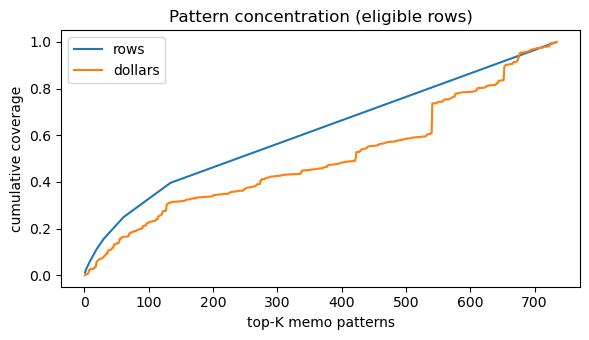

,pattern,rows,dollars,category,row_cov,dollar_cov
0,checkcard <num> boston college dining i chestnut hillma <acct>,12,116.32,Food & Drink,0.012072,0.001119
1,mcdonald's,8,125.49,Food & Drink,0.020121,0.002327
2,-eleven,7,98.69,Uncertain - Ambiguous Merchant,0.027163,0.003276
3,transfer from chime savings account,6,232.33,Transfers,0.033199,0.005512
4,internet banking fulfill request <id> payper inc.,6,116.60,Uncertain - Ambiguous Merchant,0.039235,0.006634
5,paypal type: inst xfer id: <id> co: paypal name: [name] ach ecc web,6,100.75,Transfers,0.045272,0.007604
6,zelle payment from [name] <id>,6,1105.00,Transfers,0.051308,0.018236
7,zelle payment to [name] <id>,5,670.00,Transfers,0.056338,0.024684
8,uber,5,33.74,Travel,0.061368,0.025008
9,uber eats help.uber.com ca <date>,5,166.94,Food & Drink,0.066398,0.026615


In [5]:
pat = (eligible.groupby("pattern")
       .agg(rows=("item_id", "size"), dollars=("amount", "sum"), category=("category", "first"))
       .sort_values("rows", ascending=False).reset_index())
pat["row_cov"] = pat["rows"].cumsum() / pat["rows"].sum()
pat["dollar_cov"] = pat["dollars"].cumsum() / pat["dollars"].sum()

for k in [10, 25, 50, 100, 200]:
    r = pat.iloc[min(k, len(pat)) - 1]
    print(f"top {k:>3} patterns -> {r.row_cov:6.1%} of rows, {r.dollar_cov:6.1%} of dollars")
print(f"{len(pat)} distinct patterns for {len(eligible)} rows; "
      f"{(pat.rows == 1).mean():.0%} of patterns appear once")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, len(pat) + 1), pat["row_cov"], label="rows")
ax.plot(np.arange(1, len(pat) + 1), pat["dollar_cov"], label="dollars")
ax.set_xlabel("top-K memo patterns"); ax.set_ylabel("cumulative coverage"); ax.legend()
ax.set_title("Pattern concentration (eligible rows)")
plt.tight_layout(); plt.savefig(OUT / "pareto.png", dpi=150); plt.show()
pat.head(15)

## 4. FastText files
Same split for every experiment: `train` → fit, `val` → choose settings, `test_A` / `test_B` untouched until the end.

In [6]:
def to_label(category):
    return "__label__" + re.sub(r"[^a-z0-9]+", "_", category.lower()).strip("_")

def from_label(label):
    return LABEL_NAMES[label]

LABEL_NAMES = {to_label(c): c for c in df["category"].unique()}
splits = {s: eligible[eligible["split"] == s] for s in ["train", "val", "test_A", "test_B"]}

def write_ft(frame, text_col, path):
    with open(path, "w") as f:
        for cat, text in zip(frame["category"], frame[text_col]):
            f.write(f"{to_label(cat)} {text}\n")

for text_col in ["text_lower", "text_norm"]:
    for s, frame in splits.items():
        write_ft(frame, text_col, FT_DIR / f"{s}_{text_col}.txt")

{s: len(f) for s, f in splits.items()}

{'train': 679, 'val': 135, 'test_A': 90, 'test_B': 90}

In [7]:
def fit(text_col="text_lower", seed=0, **params):
    t0 = time.perf_counter()
    model = fasttext.train_supervised(input=str(FT_DIR / f"train_{text_col}.txt"),
                                      thread=1, seed=seed, verbose=0, bucket=BUCKET, **params)
    return model, time.perf_counter() - t0

def predict(model, texts):
    labels, probs = model.predict(list(texts), k=1)
    return [from_label(l[0]) for l in labels], np.clip([p[0] for p in probs], 0, 1)

def score(model, frame, text_col):
    pred, prob = predict(model, frame[text_col])
    y = frame["category"].tolist()
    present = sorted(set(y))   # macro-F1 over classes that actually appear in this split
    return {"acc": float(np.mean(np.array(pred) == np.array(y))),
            "macro_f1": float(f1_score(y, pred, labels=present, average="macro", zero_division=0))}

def run(text_col="text_lower", **params):
    rows = []
    for seed in SEEDS:
        model, secs = fit(text_col, seed, **params)
        v = score(model, splits["val"], text_col)
        tr = score(model, splits["train"], text_col)
        rows.append({"val_f1": v["macro_f1"], "val_acc": v["acc"], "train_acc": tr["acc"], "fit_s": secs})
    r = pd.DataFrame(rows)
    return {"text": text_col, **params,
            "val_f1": r.val_f1.mean(), "val_f1_sd": r.val_f1.std(), "val_acc": r.val_acc.mean(),
            "train_acc": r.train_acc.mean(), "fit_s": r.fit_s.mean()}

## 5. Baseline = last week's setting on the new labels
Last week: `wordNgrams=2, epoch=50`, lowercased memo, everything else default (`lr=0.1, dim=100`, no char n-grams).

In [8]:
BASELINE = dict(wordNgrams=2, epoch=50)
baseline = run("text_lower", **BASELINE)
print(f"{len(splits['val'])} val rows -> one row = {100/len(splits['val']):.1f} accuracy points")
pd.DataFrame([baseline]).round(3)

135 val rows -> one row = 0.7 accuracy points


,text,wordNgrams,epoch,val_f1,val_f1_sd,val_acc,train_acc,fit_s
0,text_lower,2,50,0.502,0.0,0.607,0.852,0.131


## 6. Experiments — change one group of settings at a time (slides: features → epoch/lr → dim)
Each row is the mean over 3 seeds; `val_f1_sd` shows how much the seed alone moves the score.

### 6a. Input text + feature settings (epoch=50, lr=0.1, dim=100)

In [9]:
feature_grid = []
for text_col in ["text_lower", "text_norm"]:
    for wng in [1, 2, 3]:
        for minn, maxn in [(0, 0), (3, 5), (2, 5)]:
            for minCount in [1, 2]:
                feature_grid.append(run(text_col, wordNgrams=wng, minn=minn, maxn=maxn,
                                        minCount=minCount, epoch=50))
feat = pd.DataFrame(feature_grid).sort_values("val_f1", ascending=False)
feat.round(3).head(12)

,text,wordNgrams,minn,maxn,minCount,epoch,val_f1,val_f1_sd,val_acc,train_acc,fit_s
0,text_lower,1,0,0,1,50,0.619,0.005,0.669,0.958,0.084
1,text_lower,1,0,0,2,50,0.609,0.000,0.681,0.926,0.086
31,text_norm,3,0,0,2,50,0.537,0.000,0.615,0.777,0.114
18,text_norm,1,0,0,1,50,0.536,0.000,0.637,0.913,0.079
19,text_norm,1,0,0,2,50,0.522,0.005,0.627,0.863,0.083
13,text_lower,3,0,0,2,50,0.504,0.003,0.607,0.811,0.119
6,text_lower,2,0,0,1,50,0.502,0.000,0.607,0.852,0.108
24,text_norm,2,0,0,1,50,0.496,0.007,0.607,0.849,0.121
7,text_lower,2,0,0,2,50,0.490,0.003,0.607,0.888,0.108
30,text_norm,3,0,0,1,50,0.475,0.004,0.617,0.767,0.110


In [10]:
# effect of each feature knob, averaged over the others
for knob in ["text", "wordNgrams", "minn", "minCount"]:
    print(feat.groupby(knob)[["val_f1", "val_acc"]].mean().round(3), "\n")

            val_f1  val_acc
text                       
text_lower   0.226    0.441
text_norm    0.220    0.472 

            val_f1  val_acc
wordNgrams                 
1            0.251    0.477
2            0.215    0.449
3            0.202    0.443 

      val_f1  val_acc
minn                 
0      0.516    0.623
2      0.055    0.345
3      0.098    0.401 

          val_f1  val_acc
minCount                 
1          0.220    0.453
2          0.226    0.459 



### 6b. Epoch + learning rate (best feature setting fixed)

In [11]:
best_feat = feat.iloc[0]
FEAT = dict(text_col=best_feat["text"], wordNgrams=int(best_feat["wordNgrams"]), minn=int(best_feat["minn"]),
            maxn=int(best_feat["maxn"]), minCount=int(best_feat["minCount"]))
print("features fixed:", FEAT)

lr_grid = [run(**FEAT, epoch=ep, lr=lr) for ep in [5, 25, 50, 100] for lr in [0.05, 0.1, 0.5, 1.0]]
lrs = pd.DataFrame(lr_grid)
lrs.pivot(index="epoch", columns="lr", values="val_f1").round(3)

features fixed: {'text_col': 'text_lower', 'wordNgrams': 1, 'minn': 0, 'maxn': 0, 'minCount': 1}


lr,0.05,0.10,0.50,1.00
epoch,,,,
5,0.027,0.027,0.315,0.580
25,0.084,0.386,0.636,0.651
50,0.387,0.619,0.644,0.656
100,0.624,0.635,0.647,0.638


In [12]:
lrs.sort_values("val_f1", ascending=False).round(3).head(6)

,text,wordNgrams,minn,maxn,minCount,epoch,lr,val_f1,val_f1_sd,val_acc,train_acc,fit_s
11,text_lower,1,0,0,1,50,1.0,0.656,0.005,0.696,1.0,0.085
7,text_lower,1,0,0,1,25,1.0,0.651,0.004,0.696,1.0,0.062
14,text_lower,1,0,0,1,100,0.5,0.647,0.000,0.696,1.0,0.177
10,text_lower,1,0,0,1,50,0.5,0.644,0.006,0.696,1.0,0.090
15,text_lower,1,0,0,1,100,1.0,0.638,0.013,0.699,1.0,0.154
6,text_lower,1,0,0,1,25,0.5,0.636,0.003,0.681,1.0,0.049


### 6c. Vector size (last)

In [13]:
best_lr = lrs.sort_values("val_f1", ascending=False).iloc[0]
LEARN = dict(epoch=int(best_lr["epoch"]), lr=float(best_lr["lr"]))
dims = pd.DataFrame([run(**FEAT, **LEARN, dim=d) for d in [50, 100, 200]])
dims.round(3)

,text,wordNgrams,minn,maxn,minCount,epoch,lr,dim,val_f1,val_f1_sd,val_acc,train_acc,fit_s
0,text_lower,1,0,0,1,50,1.0,50,0.645,0.002,0.696,1.0,0.088
1,text_lower,1,0,0,1,50,1.0,100,0.656,0.005,0.696,1.0,0.117
2,text_lower,1,0,0,1,50,1.0,200,0.665,0.000,0.704,1.0,0.144


### 6d. Recheck char n-grams + word bigrams at the tuned epoch / lr / dim
In 6a, char n-grams were tried at lr=0.1, where they barely trained (many more features to learn per word).
That is not a fair comparison, so give them the tuned learning settings before ruling them out.

In [14]:
DIM = int(dims.sort_values("val_f1", ascending=False).iloc[0]["dim"])
base_feat = {k: v for k, v in FEAT.items() if k not in ("minn", "maxn", "wordNgrams")}
recheck = pd.DataFrame([run(**base_feat, **LEARN, dim=DIM, wordNgrams=w, minn=mn, maxn=mx)
                        for w in [1, 2] for mn, mx in [(0, 0), (3, 5), (2, 5)]])
recheck.round(3)

,text,minCount,epoch,lr,dim,wordNgrams,minn,maxn,val_f1,val_f1_sd,val_acc,train_acc,fit_s
0,text_lower,1,50,1.0,200,1,0,0,0.665,0.000,0.704,1.0,0.139
1,text_lower,1,50,1.0,200,1,3,5,0.663,0.004,0.714,1.0,0.472
2,text_lower,1,50,1.0,200,1,2,5,0.680,0.011,0.726,1.0,0.547
3,text_lower,1,50,1.0,200,2,0,0,0.599,0.009,0.654,1.0,0.196
4,text_lower,1,50,1.0,200,2,3,5,0.654,0.005,0.704,1.0,0.487
5,text_lower,1,50,1.0,200,2,2,5,0.658,0.005,0.726,1.0,0.598


### 6e. Pick the final setting
Highest mean val macro-F1. If the top settings are within one seed-SD of each other, they are effectively tied —
this val set is small, so treat the ranking as rough.

In [15]:
all_runs = pd.concat([pd.DataFrame([baseline]), feat, lrs, dims, recheck], ignore_index=True)
all_runs.to_csv(OUT / "experiments.csv", index=False)

best_dim = recheck.sort_values("val_f1", ascending=False).iloc[0]   # recheck includes the 6c winner
FINAL = dict(text_col=best_dim["text"], wordNgrams=int(best_dim["wordNgrams"]), minn=int(best_dim["minn"]),
             maxn=int(best_dim["maxn"]), minCount=int(best_dim["minCount"]), **LEARN, dim=DIM)
print("FINAL:", FINAL)
print(f"baseline val macro-F1 {baseline['val_f1']:.3f} (acc {baseline['val_acc']:.3f})  ->  "
      f"tuned {best_dim['val_f1']:.3f} ± {best_dim['val_f1_sd']:.3f} (acc {best_dim['val_acc']:.3f})")

FINAL: {'text_col': 'text_lower', 'wordNgrams': 1, 'minn': 2, 'maxn': 5, 'minCount': 1, 'epoch': 50, 'lr': 1.0, 'dim': 200}
baseline val macro-F1 0.502 (acc 0.607)  ->  tuned 0.680 ± 0.011 (acc 0.726)


## 7. Final model — validation review

In [16]:
text_col = FINAL["text_col"]
params = {k: v for k, v in FINAL.items() if k != "text_col"}
model, fit_secs = fit(text_col, seed=0, **params)

val = splits["val"].copy()
val["pred"], val["score"] = predict(model, val[text_col])
val["correct"] = val["pred"] == val["category"]
print(classification_report(val["category"], val["pred"], zero_division=0))

                                precision    recall  f1-score   support

                    Automotive       0.00      0.00      0.00         0
             Bills & Utilities       0.67      0.50      0.57         4
                Cash Out (ATM)       1.00      1.00      1.00         1
        Debt / Credit Payments       0.76      0.59      0.67        22
            Fees & Adjustments       1.00      0.40      0.57         5
                  Food & Drink       0.74      0.82      0.78        17
                           Gas       0.75      1.00      0.86         3
                     Groceries       0.43      1.00      0.60         3
             Health & Wellness       0.00      0.00      0.00         2
             Income / Deposits       1.00      1.00      1.00         2
         Professional Services       0.50      1.00      0.67         1
                      Shopping       0.50      0.50      0.50         6
 Subscriptions & Entertainment       0.62      0.50      0.56  

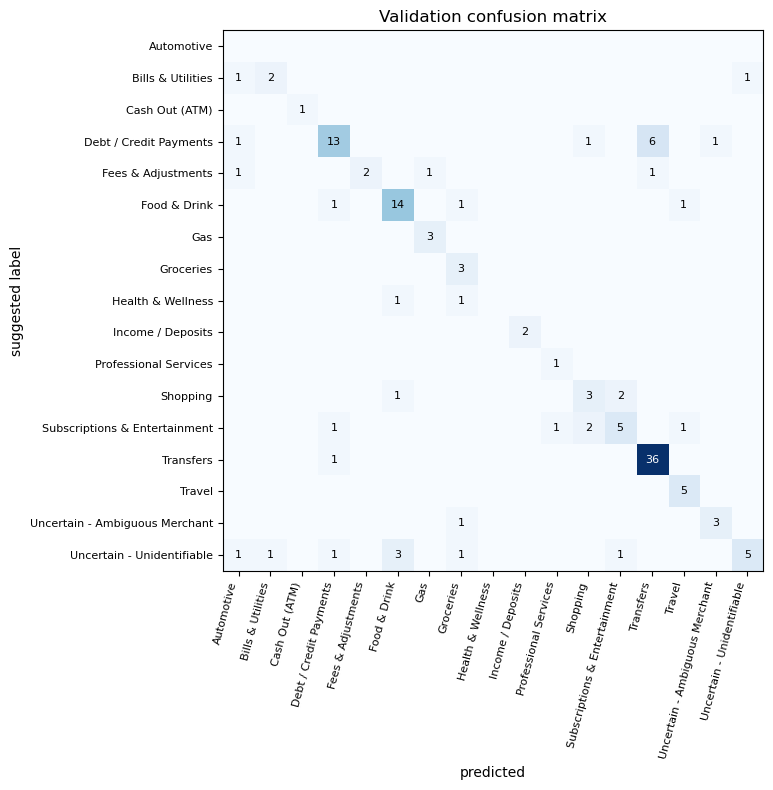

In [17]:
classes = sorted(set(val["category"]) | set(val["pred"]))
cm = confusion_matrix(val["category"], val["pred"], labels=classes)
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(classes)), classes, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(len(classes)), classes, fontsize=8)
for i in range(len(classes)):
    for j in range(len(classes)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("suggested label"); ax.set_title("Validation confusion matrix")
plt.tight_layout(); plt.savefig(OUT / "confusion.png", dpi=150); plt.show()

In [18]:
# do the errors come from merchants the model never saw?
train_patterns = set(splits["train"]["pattern"])
val["pattern_in_train"] = val["pattern"].isin(train_patterns)
print(val.groupby("pattern_in_train")["correct"].agg(["mean", "size"]).round(3))

errors = val.loc[~val["correct"], ["item_id", "memo_raw", "category", "pred", "score", "label_cue", "pattern_in_train"]]
errors.sort_values("score", ascending=False)

                   mean  size
pattern_in_train             
False             0.609    92
True              0.977    43


,item_id,memo_raw,category,pred,score,label_cue,pattern_in_train
546,n447,Transfer MoneyLion Instacash,Debt / Credit Payments,Transfers,0.999972,moneylion,False
547,n448,Transfer MoneyLion Instacash,Debt / Credit Payments,Transfers,0.999972,moneylion,False
765,n666,Grant Cash Adv 04/17 #XXXXX1186 PMNT RCVD Grant Cash Advanc,Debt / Credit Payments,Transfers,0.972889,grant cash,False
666,n567,Cleo Salary Advance VIS 0608 Oakland CA VISA MONEY TRANSFER C *5008,Debt / Credit Payments,Transfers,0.946316,cleo,False
157,n58,Point of Sale - INTERAC RETAIL PURCHASE 518208387567 TIM HORTONS #15,Food & Drink,Groceries,0.869993,tim hortons,False
575,n476,RECURRING PAYMENT AUTHORIZED ON 06/08 ABCMOUSE.COM* CA S305159407664305 CARD 0675,Subscriptions & Entertainment,Debt / Credit Payments,0.852325,abcmouse,False
796,n697,JCPenney,Shopping,Subscriptions & Entertainment,0.813094,jcpenney,False
475,n376,Dave.com P2P carlos ruvalcab WEB ID: 1475235605,Transfers,Debt / Credit Payments,0.805083,dave.com p2p,False
652,n553,CDSR,Uncertain - Unidentifiable,Subscriptions & Entertainment,0.796513,,False
752,n653,POS Purchase FPOS 22187 MACS CONV,Uncertain - Ambiguous Merchant,Groceries,0.739928,conv,False


## 8. Review cutoff (chosen on validation)
Accept the prediction when the FastText score ≥ cutoff, otherwise send to human review.
Row coverage = accepted / eligible; dollar coverage = accepted $ / eligible $.

In [19]:
cut_rows = []
for c in [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    acc = val[val["score"] >= c]
    cut_rows.append({"cutoff": c, "accepted": len(acc), "row_cov": len(acc) / len(val),
                     "dollar_cov": acc["amount"].sum() / val["amount"].sum(),
                     "accepted_error": 1 - acc["correct"].mean() if len(acc) else np.nan,
                     "to_review": len(val) - len(acc)})
cutoffs = pd.DataFrame(cut_rows)
cutoffs.round(3)

,cutoff,accepted,row_cov,dollar_cov,accepted_error,to_review
0,0.0,135,1.000,1.000,0.274,0
1,0.3,126,0.933,0.984,0.230,9
2,0.4,123,0.911,0.972,0.220,12
3,0.5,119,0.881,0.964,0.202,16
4,0.6,105,0.778,0.793,0.152,30
5,0.7,101,0.748,0.779,0.129,34
6,0.8,91,0.674,0.742,0.088,44
7,0.9,81,0.600,0.721,0.049,54


## 9. Test A and Test B — scored once with the final model

In [20]:
test_rows = []
for s in ["test_A", "test_B"]:
    t = splits[s]
    pred, prob = predict(model, t[text_col])
    sc = score(model, t, text_col)
    test_rows.append({"split": s, "rows": len(t), "accounts": t["account_key"].nunique(),
                      "correct": int((np.array(pred) == t["category"].values).sum()), **sc,
                      "pattern_in_train": t["pattern"].isin(train_patterns).mean()})
tests = pd.DataFrame(test_rows)
tests.round(3)

,split,rows,accounts,correct,acc,macro_f1,pattern_in_train
0,test_A,90,22,55,0.611,0.511,0.244
1,test_B,90,5,54,0.600,0.578,0.133


In [21]:
# class mix: compare before reading the A vs B gap
mix = pd.crosstab(eligible["category"], eligible["split"], normalize="columns")[["train", "val", "test_A", "test_B"]]
(mix * 100).round(1).sort_values("train", ascending=False)

split,train,val,test_A,test_B
category,,,,
Transfers,18.0,27.4,18.9,24.4
Food & Drink,12.2,12.6,6.7,8.9
Debt / Credit Payments,10.6,16.3,22.2,22.2
Subscriptions & Entertainment,6.8,7.4,7.8,34.4
Travel,6.0,3.7,0.0,0.0
Shopping,5.4,4.4,8.9,0.0
Groceries,5.2,2.2,5.6,1.1
Uncertain - Ambiguous Merchant,5.2,3.0,7.8,0.0
Health & Wellness,4.1,1.5,0.0,1.1


In [22]:
for s in ["test_A", "test_B"]:
    t = splits[s].copy()
    t["pred"], t["score"] = predict(model, t[text_col])
    print(f"===== {s}")
    print(classification_report(t["category"], t["pred"], zero_division=0))

===== test_A
                                precision    recall  f1-score   support

                    Automotive       0.00      0.00      0.00         0
             Bills & Utilities       0.33      0.50      0.40         2
                Cash Out (ATM)       0.60      1.00      0.75         3
        Debt / Credit Payments       1.00      0.70      0.82        20
            Fees & Adjustments       0.00      0.00      0.00         2
                  Food & Drink       0.27      0.50      0.35         6
                           Gas       0.00      0.00      0.00         1
             Gifts & Donations       0.00      0.00      0.00         0
                     Groceries       1.00      0.40      0.57         5
             Income / Deposits       1.00      0.60      0.75         5
                      Shopping       0.67      0.50      0.57         8
 Subscriptions & Entertainment       0.43      0.43      0.43         7
                     Transfers       0.84      0.9

### Test B's gambling rows
About 30% of Test B is gambling, mostly from two of the five held-out accounts. Training had only 16 gambling memos,
mostly different brands (PrizePicks, Underdog, VA Lottery) from Test B's (DraftKings, CrownCoins, Fanatics),
so the overall Test B score hides a large split.

In [23]:
gamb_rows = []
for s in ["test_A", "test_B"]:
    t = splits[s].copy()
    t["pred"], _ = predict(model, t[text_col])
    t["gambling"] = t["subcategory"].eq("gambling")
    for g, part in t.groupby("gambling"):
        gamb_rows.append({"split": s, "gambling": g, "rows": len(part),
                          "correct": int((part["pred"] == part["category"]).sum()),
                          "acc": (part["pred"] == part["category"]).mean()})
gamb = pd.DataFrame(gamb_rows)
print("gambling rows by split:", df[df.subcategory.eq("gambling")].groupby("split").size().to_dict())
print("Test B gambling rows per account:",
      splits["test_B"][splits["test_B"].subcategory.eq("gambling")]["account_key"].value_counts().to_dict())
gamb.round(3)

gambling rows by split: {'excluded': 1, 'test_A': 4, 'test_B': 27, 'train': 16, 'val': 2}
Test B gambling rows per account: {np.int64(553883): 10, np.int64(591523): 9, np.int64(108290): 4, np.int64(436401): 3, np.int64(285973): 1}


,split,gambling,rows,correct,acc
0,test_A,False,86,55,0.640
1,test_A,True,4,0,0.000
2,test_B,False,63,51,0.810
3,test_B,True,27,3,0.111


## 10. Runtime + scale
Hardware, fit time, model size, and inference throughput (single-threaded `predict` on batches of memos).

In [24]:
batch = (df[text_col].tolist() * 100)[:100_000]   # 100k memos for a stable timing
t0 = time.perf_counter(); model.predict(batch, k=1); infer_secs = time.perf_counter() - t0
with tempfile.TemporaryDirectory() as tmp:   # save only to measure size / load time; too big for GitHub
    model_path = Path(tmp) / "model.bin"
    model.save_model(str(model_path))
    model_mb = model_path.stat().st_size / 1e6
    t0 = time.perf_counter(); fasttext.load_model(str(model_path)); load_secs = time.perf_counter() - t0
rows_per_sec = len(batch) / infer_secs

runtime = {
    "hardware": f"{platform.machine()} / {platform.platform()} / python {platform.python_version()}",
    "train_rows": len(splits["train"]), "fit_seconds": round(fit_secs, 3),
    "experiments_run": int(len(all_runs) * len(SEEDS)),
    "model_mb": round(model_mb, 1), "model_load_seconds": round(load_secs, 3),
    "inference_batch": len(batch), "inference_rows_per_sec": round(rows_per_sec),
    "est_seconds_1M": round(1e6 / rows_per_sec, 1), "est_hours_2B": round(2e9 / rows_per_sec / 3600, 1),
}
runtime

{'hardware': 'arm64 / macOS-15.0.1-arm64-arm-64bit / python 3.12.8',
 'train_rows': 679,
 'fit_seconds': 0.544,
 'experiments_run': 186,
 'model_mb': 161.5,
 'model_load_seconds': 0.148,
 'inference_batch': 100000,
 'inference_rows_per_sec': 81241,
 'est_seconds_1M': 12.3,
 'est_hours_2B': 6.8}

## 11. Save outputs + personal CSV
`labels_v2_aiden.csv` = the original columns with `category`, `text_lower`, `text_norm`, `pattern` filled in,
plus the label cue and FastText's prediction for every row. Train-row predictions are in-sample
(`pred_in_sample = True`), so only val / test rows say anything about generalization.

In [25]:
df["fasttext_pred"], df["fasttext_score"] = predict(model, df[text_col])
df["fasttext_agrees"] = df["fasttext_pred"] == df["category"]
df["pred_in_sample"] = df["split"] == "train"
df.to_csv(PERSONAL_CSV, index=False)

val.loc[~val["correct"]].to_csv(OUT / "errors_val.csv", index=False)
metrics = {
    "label_status": "ai_suggested_rules (not yet human-reviewed)",
    "n_rows": {s: int(len(f)) for s, f in splits.items()},
    "classes_in_train": int(splits["train"]["category"].nunique()),
    "baseline": {k: baseline[k] for k in ["val_f1", "val_f1_sd", "val_acc", "train_acc"]},
    "final_params": FINAL,
    "final_val": {"macro_f1": float(best_dim["val_f1"]), "macro_f1_sd": float(best_dim["val_f1_sd"]),
                  "acc": float(best_dim["val_acc"])},
    "tests": tests.to_dict(orient="records"),
    "test_gambling_split": gamb.to_dict(orient="records"),
    "cutoffs_val": cutoffs.to_dict(orient="records"),
    "runtime": runtime,
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
print("wrote", PERSONAL_CSV, "and", sorted(p.name for p in OUT.iterdir()))
print(f"agreement over the WHOLE csv: {df.fasttext_agrees.mean():.1%}  <- misleading, includes in-sample train rows")
print(df.groupby("split")["fasttext_agrees"].mean().round(3).to_dict())
df[["item_id", "split", "memo_raw", "category", "label_cue", "fasttext_pred", "fasttext_score"]].head(10)

wrote labels_v2_aiden.csv and ['.DS_Store', 'confusion.png', 'errors_val.csv', 'experiments.csv', 'fasttext_files', 'metrics.json', 'pareto.png']
agreement over the WHOLE csv: 88.8%  <- misleading, includes in-sample train rows
{'excluded': 0.333, 'test_A': 0.611, 'test_B': 0.6, 'train': 1.0, 'val': 0.726}


,item_id,split,memo_raw,category,label_cue,fasttext_pred,fasttext_score
0,1,train,Zelle payment to [NAME] JPM99aa9jfks,Transfers,zelle,Transfers,0.999869
1,2,train,CASH APP*[NAME]*San FranciscoCAUS,Transfers,cash app,Transfers,1.000000
2,3,train,GOOGLE *TikTok Mountain ViewCA Card# *1210 POS DEB 0139 09/16/24 04483022,Subscriptions & Entertainment,google,Subscriptions & Entertainment,0.982988
3,4,train,ONLINE TRANSFER TO BREWER R EVERYDAY CHECKING XXXXXX2783 REF #IB0P6H3LH9 ON 08/11/24,Transfers,transfer,Transfers,0.997266
4,5,train,Internet Banking E-TRANSFER 105121339333 [NAME],Transfers,e-transfer,Transfers,0.999883
5,6,train,CASH APP*[NAME]*AD 800-9691940 CA,Transfers,cash app,Transfers,1.000000
6,7,train,Google,Subscriptions & Entertainment,google,Subscriptions & Entertainment,0.992380
7,8,train,HARRIS TE 750 05/08 #XXXXX6192 MOBILE PURCHASE HARRIS TE 750 W W APEX NC,Groceries,harris te,Groceries,0.976717
8,9,train,Withdrawal POS / AMOCO#1204300CO OAKDALE OAKDALE PA,Gas,amoco,Gas,0.954784
9,10,train,MONEY TRANSFER AUTHORIZED ON 06/19 COINBASE https://www.f CA S463171242465228 CARD 6502,Finance & Investments,coinbase,Finance & Investments,0.868699
